In [65]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

# Импорты для классического машинного обучения (k-NN)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [66]:
path_to_folder = './data'
IMAGE_SIZE = 32

images_by_class = {} 
X_vectors = []       
y_labels = []        

folders = [x[0].split('\\')[-1] for x in os.walk(path_to_folder)][1:]

for class_name in folders:
    images_by_class[class_name] = []
    class_path = os.path.join(path_to_folder, class_name)
    
    for file_name in os.listdir(class_path):
        img_path = os.path.join(class_path, file_name)
        
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if img is None:
            continue
            
        img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
        img = cv2.bitwise_not(img) / 255.0
        
        images_by_class[class_name].append(img)
        
        X_vectors.append(img.flatten())
        y_labels.append(class_name)

X_vectors = np.array(X_vectors)
y_labels = np.array(y_labels)

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ

In [67]:
def generate_synthetic_string(text, space_width=15, letter_spacing=5):
    """
    Генерирует единое изображение строки. 
    letter_spacing - межбуквенный интервал, чтобы символы не слипались для findContours.
    space_width - ширина пробела между словами.
    """
    char_blocks = []
    
    for char in text:
        if char == ' ':
            char_blocks.append(np.zeros((IMAGE_SIZE, space_width)))
        else:
            target_class = 'times' if char == '*' else char 
            
            if target_class in images_by_class and len(images_by_class[target_class]) > 0:
                random_img = random.choice(images_by_class[target_class])
                char_blocks.append(random_img)
                char_blocks.append(np.zeros((IMAGE_SIZE, letter_spacing)))
            else:
                print(f"Предупреждение: Символ '{char}' отсутствует в базе.")
                
    return np.hstack(char_blocks)

# КЛАССИФИКАЦИЯ И ПОИСК k

Поиск оптимального параметра k...
k =  1 | Точность (Accuracy): 0.9847
k =  2 | Точность (Accuracy): 0.9415
k =  3 | Точность (Accuracy): 0.9297

Выбран оптимальный классификатор: k = 1 (Точность: 0.9847)


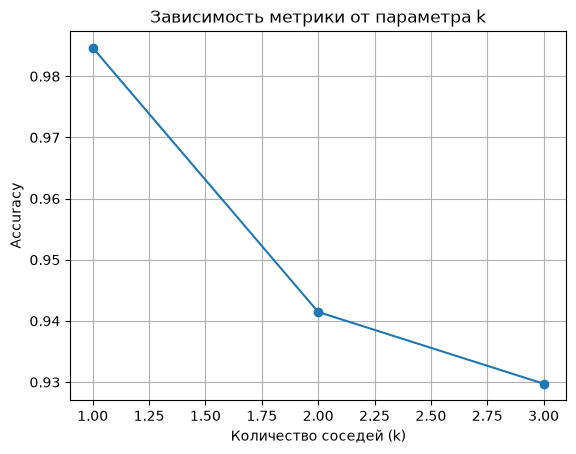

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectors, y_labels, test_size=0.3, random_state=42
)

best_k = 1
best_accuracy = 0
accuracies = []

print("Поиск оптимального параметра k...")
for k in range(1, 4):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    
    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    
    print(f"k = {k:2d} | Точность (Accuracy): {acc:.4f}")
    if acc > best_accuracy:
        best_accuracy = acc
        best_k = k

print(f"\nВыбран оптимальный классификатор: k = {best_k} (Точность: {best_accuracy:.4f})")

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)

plt.plot(range(1, 4), accuracies, marker='o')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Accuracy')
plt.title('Зависимость метрики от параметра k')
plt.grid()
plt.show()

# ГЕНЕРАЦИЯ СТРОКИ И ВЫДЕЛЕНИЕ ОБЪЕКТОВ

Выделено символов: 5


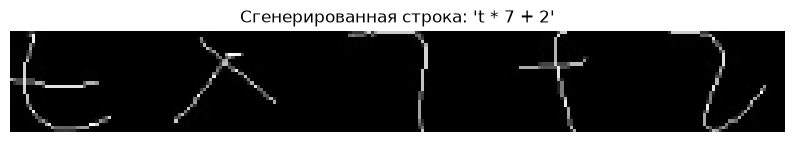

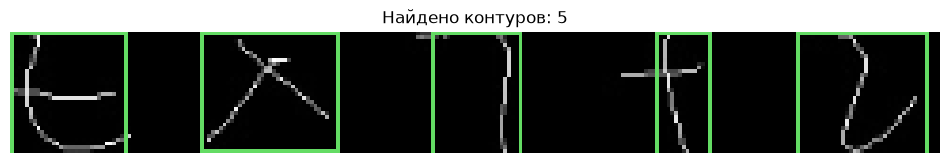

In [105]:
target_text = "t * 7 + 2" 
inference_img = generate_synthetic_string(target_text)

img_uint8 = (inference_img * 255).astype(np.uint8)

ret, thresh = cv2.threshold(img_uint8, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((5, 5), np.uint8)
thresh_dilated = cv2.dilate(thresh, kernel, iterations=1)

contours, h = cv2.findContours(thresh_dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

debug_img = cv2.cvtColor(img_uint8, cv2.COLOR_GRAY2RGB)

crops = []
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    if w * h > 160: 
        crops.append((x, y, w, h))
        cv2.rectangle(debug_img, (x, y), (x+w, y+h), (100, 220, 100), 1)

crops = sorted(crops, key=lambda c: c[0])
print(f"Выделено символов: {len(crops)}")

plt.figure(figsize=(10, 3))
plt.imshow(inference_img, cmap="gray")
plt.title(f"Сгенерированная строка: '{target_text}'")
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 3))
plt.imshow(debug_img)
plt.title(f"Найдено контуров: {len(crops)}")
plt.axis("off")
plt.show()


# РАСПОЗНАВАНИЕ И РЕЗУЛЬТАТ

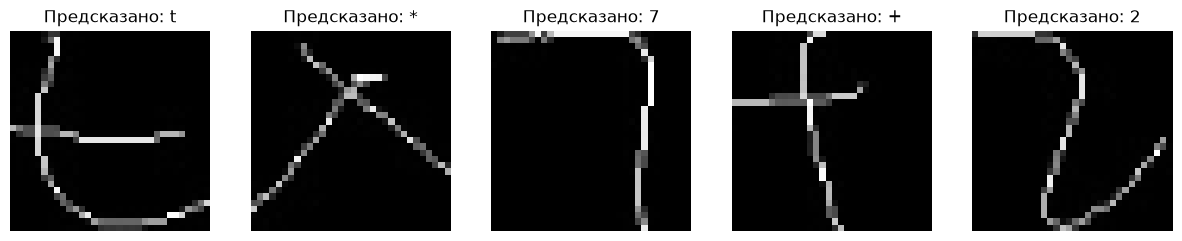

Ожидалось:  t*7+2
Распознано: t*7+2


In [106]:
recognized_chars = []

plt.figure(figsize=(15, 4))
for idx, (x, y, w, h) in enumerate(crops):
    cx = x + w // 2
    
    x_start = max(0, cx - IMAGE_SIZE // 2)
    x_end = x_start + IMAGE_SIZE
    
    if x_end > img_uint8.shape[1]:
        x_end = img_uint8.shape[1]
        x_start = x_end - IMAGE_SIZE
        
    crop_img = img_uint8[:, x_start:x_end]
    
    if crop_img.shape[1] < IMAGE_SIZE:
        padded = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
        padded[:, :crop_img.shape[1]] = crop_img
        crop_img = padded

    vector = (crop_img / 255.0).flatten().reshape(1, -1)
    
    prediction = best_knn.predict(vector)[0]
    if prediction == 'times':
        prediction = '*'
        
    recognized_chars.append(prediction)
    
    plt.subplot(1, len(crops), idx + 1)
    plt.imshow(crop_img, cmap="gray")
    plt.title(f"Предсказано: {prediction}")
    plt.axis("off")

plt.show()

final_result = "".join(recognized_chars)
print(f"Ожидалось:  {target_text.replace(' ', '')}")
print(f"Распознано: {final_result}")